In [13]:
import reframed
import cobra
import pandas as pd
import numpy as np
from os import listdir
import warnings
import seaborn as sns
from collections import OrderedDict
import json
import os
import matplotlib.pyplot as plt

In [2]:
import math

In [3]:
from reframed.core.model import ReactionType
from reframed.solvers import solver_instance
from math import inf, isinf
from reframed.community.solution import CommunitySolution
from reframed.solvers.solution import Status
from numpy.random import lognormal
from reframed.core.elements import molecular_weight

import argparse
import textwrap
from reframed.community.model import Community
from reframed.solvers.solution import Status

import glob
import pandas as pd
from reframed.io.cache import ModelCache

from reframed import Environment, set_default_solver
from math import inf

import steadiercom.steadiercom as steadiercom
from steadiercom.steadiercom import allocation_constraints
from steadiercom.cli import load_communities,load_media_db
from steadiercom.steadiercom import build_problem 

In [4]:
def SteadierSample(community, objective=None,n=100, growth=0.1, abundance=None, allocation=False, constraints=None,
             w_e=0.002, w_r=0.2, solver=None):

    if abundance:
        norm = sum(abundance.values())
        abundance = {org_id: abundance.get(org_id, 0) / norm for org_id in community.organisms}

    if not solver:
        solver = build_problem(community, growth=growth, abundance=abundance)

    if not allocation:
        w_e, w_r = 0, 0

    random_vars = allocation_constraints(community, solver, w_e=w_e, w_r=w_r, abundance=abundance)

    sols = []
    if abundance:
        w1 = {org_id: 1 / abundance[org_id] if abundance[org_id] > 0 else 0 for org_id in community.organisms}


    #if growth is None and objective is None:
    objective = community.merged_model.biomass_reaction


    dicts={}
    j=0
    
    for i in range(n):
        #if np.mod(i,100)==0:
        print(f"Round {i}")
        objective = {vi: w1[org_id] * lognormal(0, 1) for org_id, v_org in random_vars.items() for vi in v_org}

        sol = solver.solve(objective, minimize=True, constraints=constraints)

        if sol.status == Status.OPTIMAL:
            if sol.values[community.merged_model.biomass_reaction] > 0:
                sol = CommunitySolution(community, sol.values)
                dicts[i]=sol.exchange_map
        
        if np.mod(i,200)==0 and i!=0:
               
            sol_df=pd.DataFrame.from_dict(dicts)
            sol_df.to_csv("../output/Venturelli2018/performance_statistics_test/sol_df"+str(j)+".tsv",sep="\t")
            j+=1
            del dicts
            dicts = {}            
        

### Run SteadierSample

In [5]:
mediadb = "../data/Venturelli2018/generated/media_db_lb_extend.tsv"#path to mediadb
media = ["LB_extend"]
growth = 0.039683# growth rate
target = None

models = ["../models/species_used/"+name for name in listdir("../models/species_used_noO2/")]
communities = "../data/Venturelli2018/generated/communities_12_exp_abundance.tsv"

comm_id = "NONE"

### Read data 

In [6]:
direct = os.listdir("../output/Venturelli2018/performance_statistics_test/")

In [7]:
dfs = []
for d in direct:
    if d.endswith(".tsv"):
        df = pd.read_csv("../output/Venturelli2018/performance_statistics_test/"+str(d),sep="\t",index_col=(0,1))
        dfs.append(df)

In [8]:
dfs_tot = pd.concat(dfs,axis=1)

dfs_tot = dfs_tot.T.drop_duplicates().T

dfs_tot.columns = np.arange(0,dfs_tot.shape[1])
dfs_tot = dfs_tot.fillna(0)
dfs_tot

0     \
Collinsella_aerofaciens_ATCC_25986    M_7a_czp__91__e__93__         0.000016   
Bacteroides_thetaiotaomicron_VPI_5482 M_7a_czp__91__e__93__        -0.016117   
Blautia_hydrogenotrophica_DSM_10507   M_ac__91__e__93__             0.009550   
Bacteroides_ovatus_ATCC_8483          M_ac__91__e__93__             0.000658   
Bacteroides_vulgatus_ATCC_8482        M_ac__91__e__93__             0.009079   
...                                                                      ...   
Bacteroides_thetaiotaomicron_VPI_5482 M_prx_mII_glc__91__e__93__    0.000000   
                                      M_5oh_sulfp__91__e__93__      0.000000   
                                      M_5oh_sulfp_glc__91__e__93__  0.000000   
Bacteroides_vulgatus_ATCC_8482        M_clobi_c__91__e__93__        0.000000   
                                      M_clobi_glc__91__e__93__      0.000000   

                                                                    1     \
Collinsella_aerofaciens_ATCC_25986    M_7a_czp__91__e__93__          0.0   
Bacteroides_thetaiotaomicron_VPI_5482 M_7a_czp__91__e__93__          0.0   
Blautia_hydrogenotrophica_DSM_10507   M_ac__91__e__93__              0.0   
Bacteroides_ovatus_ATCC_8483          M_ac__91__e__93__              0.0   
Bacteroides_vulgatus_ATCC_8482        M_ac__91__e__93__              0.0   
...                                                                  ...   
Bacteroides_thetaiotaomicron_VPI_5482 M_prx_mII_glc__91__e__93__     0.0   
                                      M_5oh_sulfp__91__e__93__       0.0   
                                      M_5oh_sulfp_glc__91__e__93__   0.0   
Bacteroides_vulgatus_ATCC_8482        M_clobi_c__91__e__93__         0.0   
                                      M_clobi_glc__91__e__93__       0.0   

                                                                        2     \
Collinsella_aerofaciens_ATCC_25986    M_7a_czp__91__e__93__        -0.000321   
Bacteroides_thetaiotaomicron_VPI_5482 M_7a_czp__91__e__93__         0.000000   
Blautia_hydrogenotrophica_DSM_10507   M_ac__91__e__93__             0.000000   
Bacteroides_ovatus_ATCC_8483          M_ac__91__e__93__             0.079489   
Bacteroides_vulgatus_ATCC_8482        M_ac__91__e__93__             0.000056   
...                                                                      ...   
Bacteroides_thetaiotaomicron_VPI_5482 M_prx_mII_glc__91__e__93__    0.000000   
                                      M_5oh_sulfp__91__e__93__      0.000000   
                                      M_5oh_sulfp_glc__91__e__93__  0.000000   
Bacteroides_vulgatus_ATCC_8482        M_clobi_c__91__e__93__        0.000000   
                                      M_clobi_glc__91__e__93__      0.000000   

                                                                        3     \
Collinsella_aerofaciens_ATCC_25986    M_7a_czp__91__e__93__         0.000000   
Bacteroides_thetaiotaomicron_VPI_5482 M_7a_czp__91__e__93__         0.000000   
Blautia_hydrogenotrophica_DSM_10507   M_ac__91__e__93__             0.015251   
Bacteroides_ovatus_ATCC_8483          M_ac__91__e__93__             0.000658   
Bacteroides_vulgatus_ATCC_8482        M_ac__91__e__93__             0.000000   
...                                                                      ...   
Bacteroides_thetaiotaomicron_VPI_5482 M_prx_mII_glc__91__e__93__    0.000000   
                                      M_5oh_sulfp__91__e__93__      0.000000   
                                      M_5oh_sulfp_glc__91__e__93__  0.000000   
Bacteroides_vulgatus_ATCC_8482        M_clobi_c__91__e__93__        0.000000   
                                      M_clobi_glc__91__e__93__      0.000000   

                                                                        4     \
Collinsella_aerofaciens_ATCC_25986    M_7a_czp__91__e__93__         0.000000   
Bacteroides_thetaiotaomicron_VPI_5482 M_7a_czp__91__e__93__         0.000000   
Blautia_hydrogenotrophica_DSM_10507 

In [23]:
np.logspace(1,3.2,25)

array([  10.        ,   12.34999173,   15.25222957,   18.83649089,
         23.26305067,   28.72984833,   35.48133892,   43.81942422,
         54.11695265,   66.83439176,   82.54041853,  101.93734859,
        125.89254118,  155.4771842 ,  192.01419386,  237.13737057,
        292.86445646,  361.68736144,  446.68359215,  551.65386676,
        681.29206906,  841.39514165, 1039.12230384, 1283.31518556,
       1584.89319246])

In [131]:
statistics = {}
datas = {}
for n in np.logspace(1,3.2,25):
    sample_size = int(n)

    number = math.floor(dfs_tot.shape[1]/sample_size)
    data = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})


    equal_zero= data.sum(axis=1).apply(abs).sort_values() <1e-4
    data = data.loc[~equal_zero]
    
    cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 
    data = data.T.apply(cv)
    datas[sample_size]=data    
    
    median = data.median()
    mean = data.mean()
    max_ = data.max()
    min_ = data.min()
    statistics[sample_size] = {"mean":mean,
                               "median":median,
                               "max":max_,
                               "min":min_}

In [132]:
datas_df = pd.DataFrame(datas)


(0.0, 5000.0)

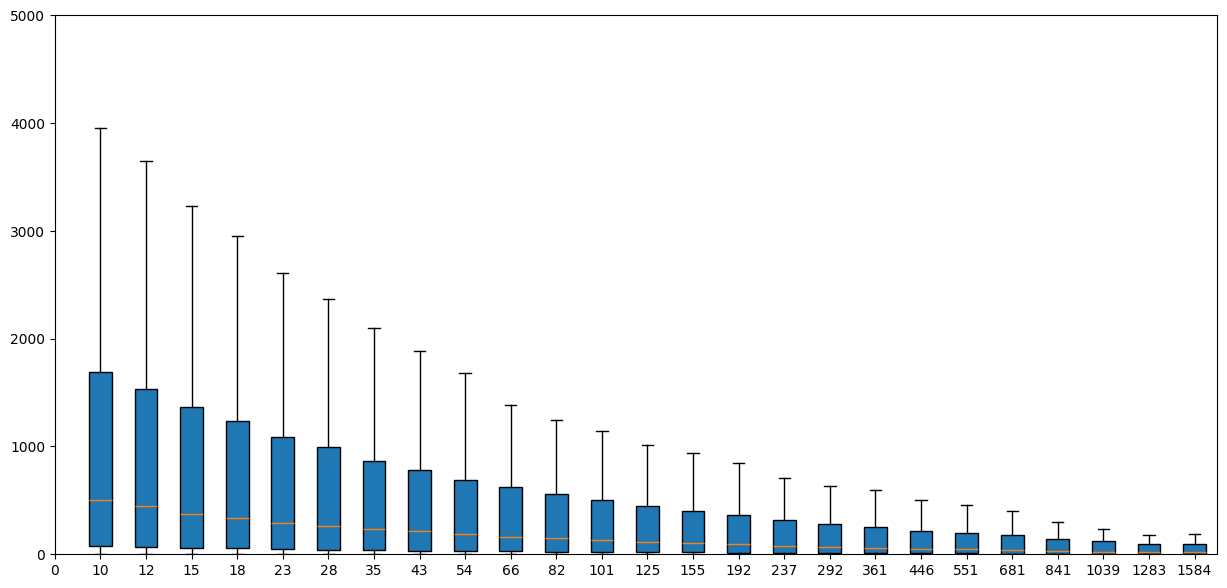

In [133]:
fig = plt.figure(figsize =(15, 7))
ax = fig.add_subplot(111)
bp = ax.boxplot(datas.values(),notch=False, patch_artist = True, vert = 0,sym='')
strings = [0]
for key in datas.keys(): 
    strings.append(str(key))
ticks = ax.set_xticks(np.arange(0,26),strings)
ax.set_ylim([0,5000])

(0.0, 500.0)

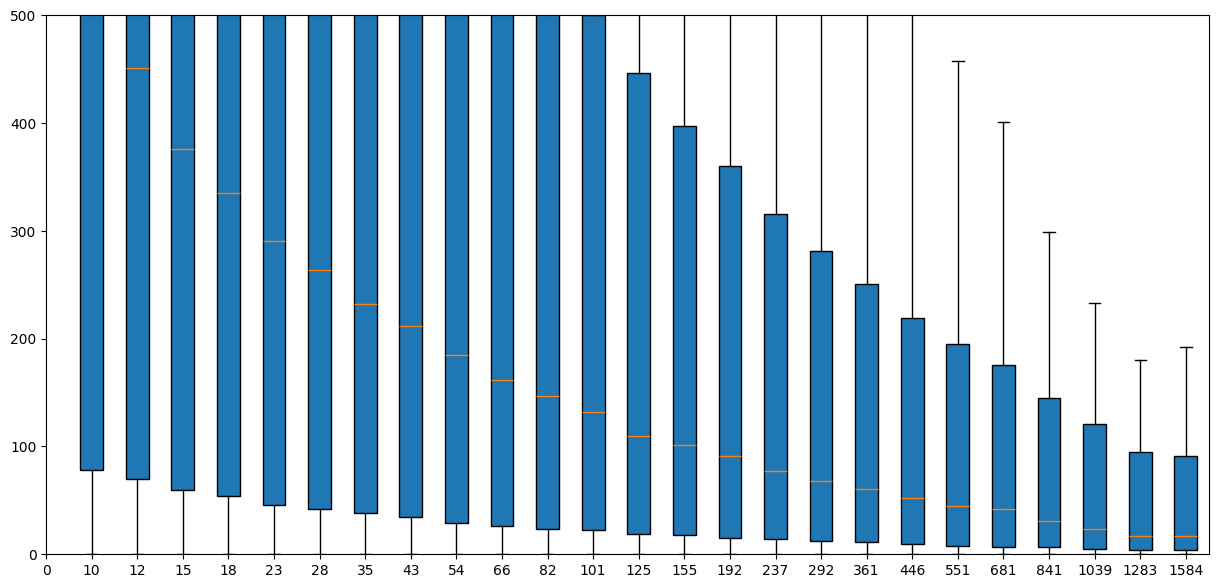

In [134]:
fig = plt.figure(figsize =(15, 7))
ax = fig.add_subplot(111)
bp = ax.boxplot(datas.values(),notch=False, patch_artist = True, vert = 0,sym='')
strings = [0]
for key in datas.keys(): 
    strings.append(str(key))
ticks = ax.set_xticks(np.arange(0,26),strings)
ax.set_ylim([0,500])

<Axes: >

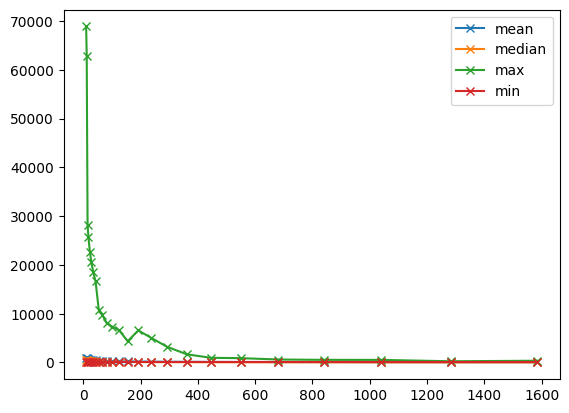

In [135]:
statistics_df = pd.DataFrame(statistics).T
statistics_df.plot(marker="x")

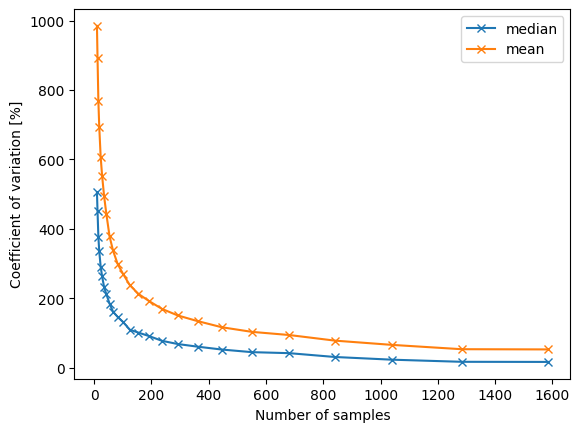

In [136]:
ax = statistics_df[["median","mean"]].plot(marker="x")
ax.set_ylabel("Coefficient of variation [%]")
ax.set_xlabel("Number of samples")
plt.savefig("figures/convergence.png")

<Axes: >

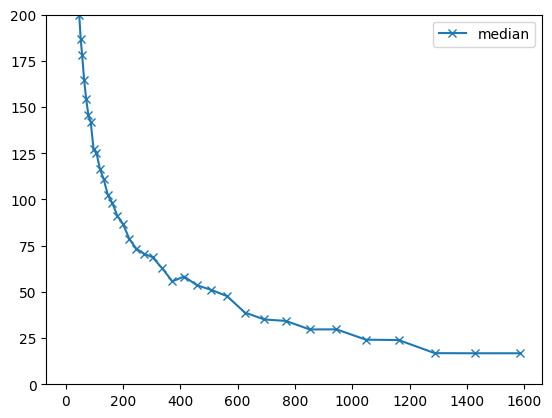

In [12]:
statistics_df[[column for column in statistics_df.columns if column=="median" ]].plot(marker="x",ylim=[0,200])

In [219]:
statistics = {}

for n in [100,250,500,800,1000,1200]:
    b = -6
    
    statistics[n]={}
    for a in np.linspace(-5.5,0,12):

        sample_size = int(n)
        number = math.floor(dfs_tot.shape[1]/sample_size)


        data = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})

        data_set_lower= data.mean(axis=1).apply(abs).sort_values() <10**(a)
        data_set_upper = data.mean(axis=1).apply(abs).sort_values() >10**(b)
        data_bound = data_set_lower * data_set_upper
        data = data.loc[data_bound]

        cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 
        data = data.T.apply(cv)


        median = data.median()

        statistics[n][(round(10**b,6),round(10**a,6))] =median
        b=a

In [220]:
import matplotlib.pyplot as plt

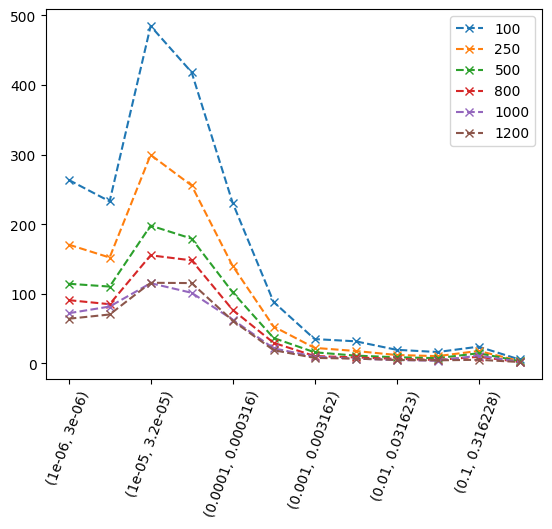

In [221]:
pd.DataFrame(statistics).plot(marker="x",linestyle="--")
xticks = plt.xticks(rotation=70)

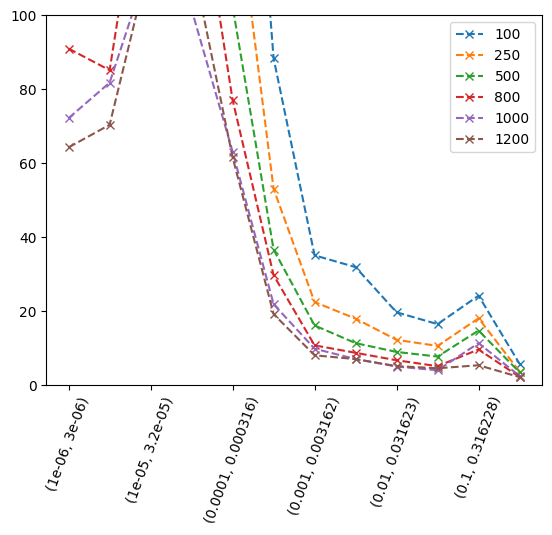

In [222]:
pd.DataFrame(statistics).plot(marker="x",linestyle="--",ylim=[0,100])
xticks = plt.xticks(rotation=70)